# Chapitre 9 - Cours 3 : PRIM, MARS, mélanges d'experts et données manquantes

Ce dernier notebook de cours couvre les sections 9.3 à 9.7 du livre :

1. **PRIM** (*patient rule induction method*), la recherche de « bosses » par
   épluchage de boîtes (algorithme 9.3, figures 9.7 et 9.8, exemple spam) ;
2. **MARS** (*multivariate adaptive regression splines*) : fonctions charnières,
   passe avant, passe arrière avec GCV, scénarios simulés (table 9.4), lien avec CART ;
3. les **mélanges hiérarchiques d'experts** (HME), version « douce » des arbres, avec un
   petit ajustement par l'algorithme EM ;
4. les **données manquantes** : mécanismes MCAR / MAR, imputation, coupures de
   substitution des arbres ;
5. les coûts de calcul des différentes méthodes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (prim_peel, prim_paste, prim, in_box, box_rules, MARS,
                             ArbreCART, SPAM_NAMES)

set_style()
rng = np.random.RandomState(0)

## 1. PRIM : la chasse aux bosses

Les arbres de régression cherchent des boîtes dont les moyennes de réponse sont **aussi
différentes que possible**. PRIM cherche plutôt des boîtes où la moyenne de la réponse
est **élevée** : il vise les **maxima** de la fonction cible (*bump hunting*). Pour
chercher des minima, il suffit de changer $y$ en $-y$.

Autre différence : les boîtes de PRIM ne sont **pas** organisées en arbre binaire. Leur
ensemble est un peu moins facile à interpréter, mais chaque règle est souvent plus
simple.

### L'algorithme 9.3

1. Partir de toutes les données et de la boîte maximale qui les contient.
2. **Épluchage** : envisager de comprimer la boîte sur une de ses faces, de façon à
   retirer la fraction $\alpha$ des observations ayant les plus grandes (ou les plus
   petites) valeurs d'une variable $X_j$. Retenir l'épluchage qui donne la plus grande
   moyenne de réponse dans la boîte restante ($\alpha = 0.05$ ou $0.10$ typiquement).
3. Répéter l'étape 2 jusqu'à ce qu'il reste un nombre minimal d'observations (10, par
   exemple).
4. **Recollage** : élargir la boîte le long d'une face tant que cela augmente la
   moyenne de la boîte.
5. Ces étapes donnent une suite de boîtes d'effectifs décroissants ; on en choisit une
   par validation croisée (et jugement de l'analyste) : c'est $B_1$.
6. Retirer les observations de $B_1$ et recommencer pour obtenir $B_2$, $B_3$, etc.

> **Remarque (ex-aequo).** Si une variable a beaucoup de valeurs égales (des zéros, par
> exemple), un épluchage peut retirer bien plus que la fraction $\alpha$. Notre fonction
> `prim_peel` compare alors les candidats par le **gain de moyenne par observation
> retirée**, ce qui revient au critère du livre en l'absence d'ex-aequo.

### Figure 9.7 : un exemple jouet

200 points uniformes dans le carré unité ; $Y=1$ (rouge dans le livre, orange ici) si
$0.5<X_1<0.8$ et $0.4<X_2<0.6$, et $Y=0$ sinon. On épluche $\alpha=10\,\%$ des points
restants à chaque étape.

In [2]:
Xp = rng.uniform(0, 1, (200, 2))
yp = ((Xp[:, 0] > 0.5) & (Xp[:, 0] < 0.8) & (Xp[:, 1] > 0.4) & (Xp[:, 1] < 0.6)).astype(float)
boites, moyennes, effectifs = prim_peel(Xp, yp, alpha=0.1, min_count=10)
print("nombre d'épluchages :", len(boites) - 1)
print("points dans la cible :", int(yp.sum()))

nombre d'épluchages : 25
points dans la cible : 15


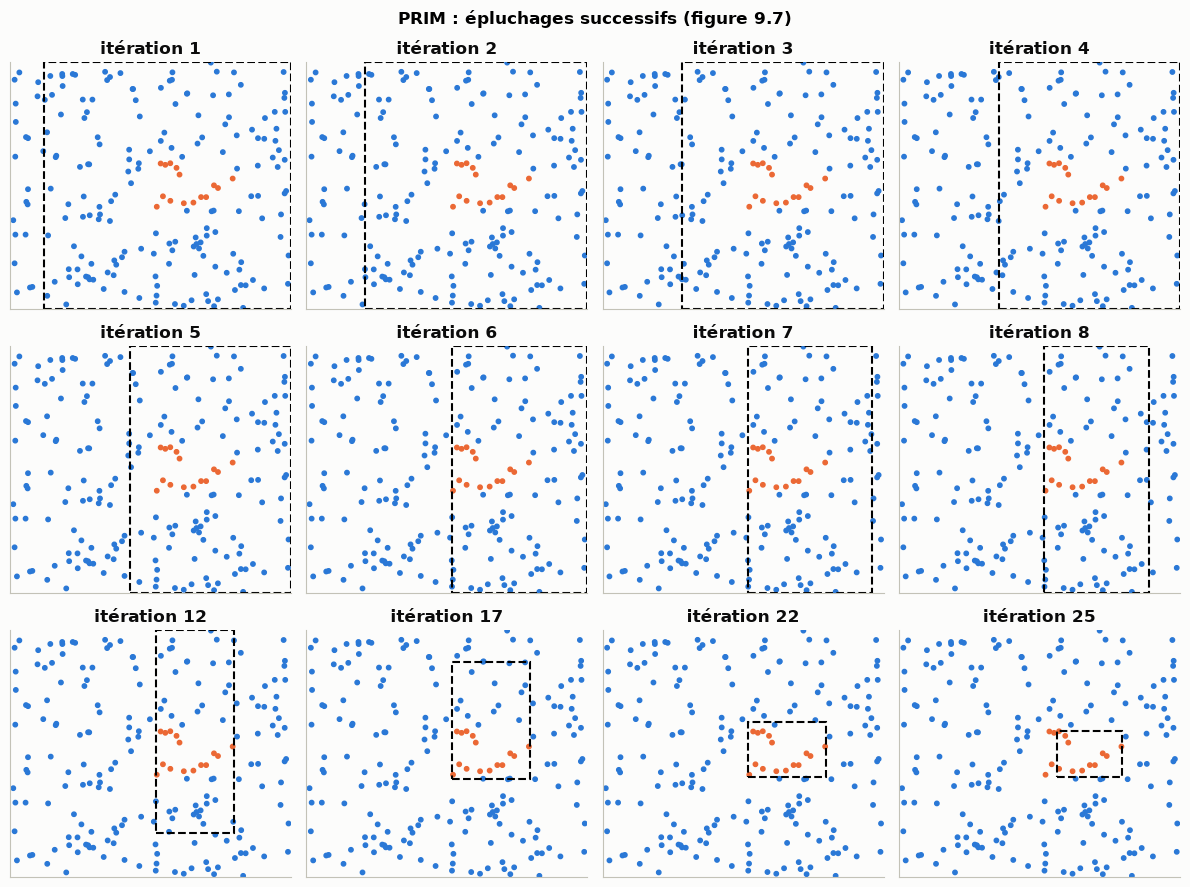

In [3]:
etapes = [1, 2, 3, 4, 5, 6, 7, 8, 12, 17, 22, len(boites) - 1]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, k in zip(axes.ravel(), etapes):
    k = min(k, len(boites) - 1)
    lo, hi = boites[k]
    lo = np.clip(lo, 0, 1)
    hi = np.clip(hi, 0, 1)
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap=TWO_CLASS, s=10)
    ax.add_patch(Rectangle(lo, *(hi - lo), fill=False, ls="--", lw=1.5, ec="k"))
    ax.set(title="itération %d" % k, xticks=[], yticks=[], xlim=(0, 1), ylim=(0, 1))
fig.suptitle("PRIM : épluchages successifs (figure 9.7)", fontweight="bold")
fig.tight_layout()
plt.show()

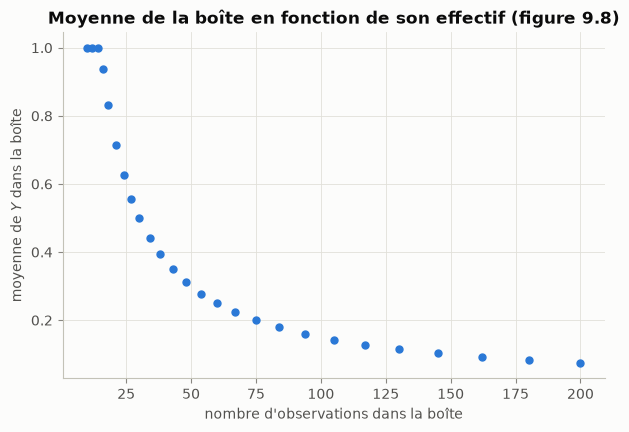

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(effectifs, moyennes, "o", color=BLUE)
ax.set(title="Moyenne de la boîte en fonction de son effectif (figure 9.8)",
       xlabel="nombre d'observations dans la boîte", ylabel="moyenne de $Y$ dans la boîte")
plt.show()

La moyenne de la boîte croît à mesure qu'on l'épluche, jusqu'à isoler une région pure
(moyenne 1).

**Recollage.** L'épluchage étant glouton, il peut avoir trop rogné une face. Sur cet
exemple très net, aucun recollage n'augmente la moyenne le long de la trajectoire :

In [5]:
n_modif = sum(in_box(Xp, prim_paste(Xp, yp, b, alpha=0.1)).sum() != in_box(Xp, b).sum()
              for b in boites)
print("boîtes de la trajectoire modifiées par le recollage :", n_modif, "sur", len(boites))

boîtes de la trajectoire modifiées par le recollage : 0 sur 26


Pour voir le recollage à l'œuvre, partons d'une boîte volontairement mal placée,
$[0.5, 0.65]\times[0.3, 0.6]$ : elle déborde sous la cible ($X_2<0.4$) et s'arrête trop
tôt à droite ($X_1<0.65$ au lieu de $0.8$).

In [6]:
b0 = (np.array([0.5, 0.3]), np.array([0.65, 0.6]))
b_rec = prim_paste(Xp, yp, b0, alpha=0.1)
for nom, b in [("avant recollage", b0), ("après recollage", b_rec)]:
    m = in_box(Xp, b)
    print("%-16s : %3d points, moyenne %.3f, règles %s" % (nom, m.sum(), yp[m].mean(),
                                                         box_rules(b, ["X1", "X2"])))

avant recollage  :  11 points, moyenne 0.818, règles ['0.5 < X1 < 0.65', '0.3 < X2 < 0.6']
après recollage  :  13 points, moyenne 0.846, règles ['0.5 < X1 < 0.688', '0.3 < X2 < 0.6']


Le recollage a élargi la face droite (vers $X_1=0.8$), ce qui ajoute des points de la
cible et augmente la moyenne de la boîte.

### La « patience » de PRIM

Avec $N$ observations et des coupures en deux moitiés égales, CART ne peut faire que
$\log_2(N)-1$ coupures successives avant d'épuiser les données. PRIM, qui ne retire que
la fraction $\alpha$ à chaque étape, peut en faire environ $-\log(N)/\log(1-\alpha)$
(on résout $N(1-\alpha)^k = 1$). Pour $N=128$ et $\alpha=0.1$ :

In [7]:
N, a = 128, 0.1
print("CART : log2(N) - 1 = %d" % (np.log2(N) - 1))
print("PRIM : -log(N)/log(1 - alpha) = %.1f" % (-np.log(N) / np.log(1 - a)))
n, k = N, 0
while n >= 2:
    n -= int(np.ceil(a * n))  # on retire un nombre entier d'observations
    k += 1
print("PRIM avec des effectifs entiers : %d épluchages" % k)

CART : log2(N) - 1 = 6
PRIM : -log(N)/log(1 - alpha) = 46.1
PRIM avec des effectifs entiers : 29 épluchages


Avec des effectifs entiers (on retire au moins une observation à chaque étape), on
retrouve les **29** épluchages du livre. Cette patience aide l'algorithme glouton à
trouver une meilleure solution.

### PRIM sur les données spam

Réponse codée 1 (spam) / 0 (email), même partage apprentissage / test que dans les
notebooks précédents. Pour choisir la boîte dans la trajectoire d'épluchage (étape 5),
nous retenons la plus petite boîte contenant encore au moins 10 % des données
d'apprentissage (un choix simple qui remplace ici la validation croisée).

In [8]:
spam = datasets.load_spam()
X = spam.drop(columns="spam").to_numpy(float)
y = spam["spam"].to_numpy()
perm = np.random.RandomState(0).permutation(len(y))
test, train = perm[:1536], perm[1536:]
Xtr, ytr, Xte, yte = X[train], y[train].astype(float), X[test], y[test].astype(float)

def choix_support(boxes, means, counts):
    return int(np.max(np.where(counts >= 0.10 * len(ytr))[0]))

regles = prim(Xtr, ytr, n_boxes=2, alpha=0.1, min_count=10, select=choix_support)

In [9]:
dispo_te = np.ones(len(yte), bool)
for r_i, r in enumerate(regles, 1):
    m_te = dispo_te & in_box(Xte, r["box"])
    print("Règle %d : %s" % (r_i, " ET ".join(box_rules(r["box"], SPAM_NAMES))))
    print("   apprentissage : moyenne restante %.3f, moyenne de la boîte %.3f, support %.3f"
          % (r["remain_mean"], r["mean"], r["count"] / len(ytr)))
    print("   test          : moyenne restante %.3f, moyenne de la boîte %.3f, support %.3f"
          % (yte[dispo_te].mean(), yte[m_te].mean(), m_te.sum() / len(yte)))
    dispo_te &= ~m_te

Règle 1 : remove > 0.01 ET internet < 0.505 ET mail < 1.1 ET your > 0.325 ET ch! > 0.069
   apprentissage : moyenne restante 0.389, moyenne de la boîte 0.994, support 0.100
   test          : moyenne restante 0.405, moyenne de la boîte 0.993, support 0.091
Règle 2 : money > 0.01
   apprentissage : moyenne restante 0.321, moyenne de la boîte 0.892, support 0.109
   test          : moyenne restante 0.346, moyenne de la boîte 0.902, support 0.113


Comme dans le livre, la première boîte est presque purement composée de spams et
contient de l'ordre de 10 à 15 % des messages ; la seconde est un peu moins pure. Les
moyennes test sont proches des moyennes d'apprentissage : les boîtes ne sur-apprennent
pas trop. Les règles exactes diffèrent de celles du livre (autre partage des données,
autre règle de choix de la boîte), mais leur style est le même : quelques inégalités
simples, sans structure d'arbre.

## 2. MARS : régression multivariée par splines adaptatives

MARS est une méthode de régression adaptée aux grandes dimensions. On peut la voir comme
une **régression pas à pas** sur un dictionnaire de fonctions, ou comme une modification
de CART qui corrige ses défauts en régression (manque de régularité, effets additifs).

### Les fonctions charnières

MARS utilise des fonctions affines par morceaux $(x-t)_+$ et $(t-x)_+$, où $u_+ =
\max(u,0)$ désigne la partie positive :
$$(x-t)_+ = \begin{cases}x-t & \text{si } x>t,\\ 0 & \text{sinon,}\end{cases}\qquad
(t-x)_+ = \begin{cases}t-x & \text{si } x<t,\\ 0 & \text{sinon.}\end{cases}$$
Ce sont des **splines linéaires** à un nœud $t$ ; on appelle ces deux fonctions une
**paire réfléchie**.

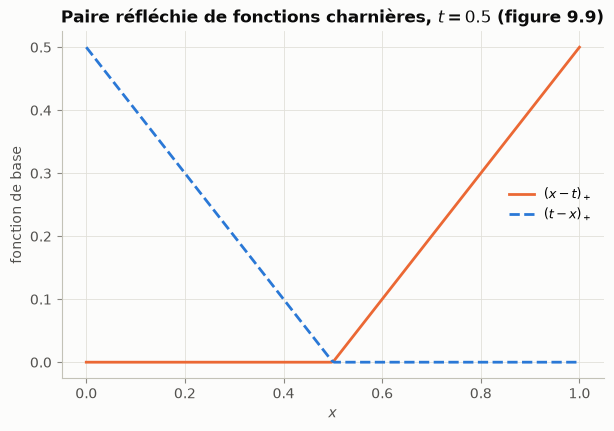

In [10]:
xg = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xg, np.maximum(xg - 0.5, 0), color=ORANGE, label="$(x-t)_+$")
ax.plot(xg, np.maximum(0.5 - xg, 0), color=BLUE, ls="--", label="$(t-x)_+$")
ax.set(title="Paire réfléchie de fonctions charnières, $t=0.5$ (figure 9.9)",
       xlabel="$x$", ylabel="fonction de base")
ax.legend()
plt.show()

On forme une paire réfléchie pour chaque variable $X_j$ et **chaque valeur observée**
$x_{ij}$ comme nœud (éq. (9.18)) :
$$\mathcal C = \big\{(X_j-t)_+,\ (t-X_j)_+\big\}_{t\in\{x_{1j},\dots,x_{Nj}\},\
j=1,\dots,p},$$
soit $2Np$ fonctions si toutes les valeurs sont distinctes. Chacune ne dépend que d'une
variable mais est vue comme une fonction sur tout $\mathbb R^p$.

### La passe avant

Le modèle est de la forme (éq. (9.19))
$$f(X) = \beta_0 + \sum_{m=1}^M \beta_m h_m(X),$$
où chaque $h_m$ est une fonction de $\mathcal C$ ou un **produit** de telles fonctions.
Les $h_m$ étant choisies, les $\beta_m$ s'obtiennent par moindres carrés ordinaires.

On part de $\mathcal M = \{h_0 = 1\}$. À chaque étape, on considère tous les produits
d'une fonction $h_\ell\in\mathcal M$ par une paire réfléchie de $\mathcal C$ et l'on
ajoute au modèle la paire
$$\hat\beta_{M+1}\,h_\ell(X)(X_j-t)_+ + \hat\beta_{M+2}\,h_\ell(X)(t-X_j)_+$$
qui fait **le plus baisser** la somme des carrés résiduelle. On s'arrête à un nombre
maximal de termes.

Deux règles complètent la passe avant :

- une variable apparaît **au plus une fois** dans un produit (pas de puissances
  $X_j^2$, qui varient trop vite au bord du domaine) ;
- on peut borner le **degré d'interaction** (2 = produits de deux charnières au plus ;
  1 = modèle additif).

La construction est **hiérarchique** : un produit de quatre facteurs ne peut apparaître
que si l'un de ses « sous-produits » à trois facteurs est déjà dans le modèle.

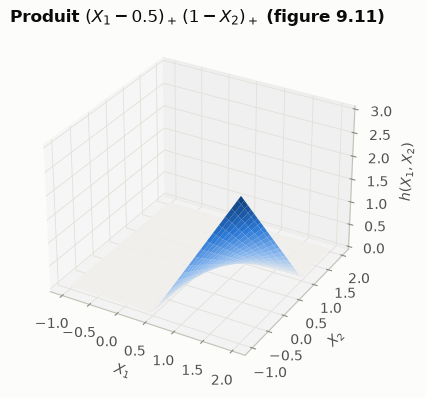

In [11]:
g1, g2 = np.meshgrid(np.linspace(-1, 2, 60), np.linspace(-1, 2, 60))
h = np.maximum(g1 - 0.5, 0) * np.maximum(1.0 - g2, 0)
fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(g1, g2, h, cmap=SEQ, linewidth=0)
ax.set(xlabel="$X_1$", ylabel="$X_2$", zlabel="$h(X_1,X_2)$",
       title="Produit $(X_1-0.5)_+\\,(1-X_2)_+$ (figure 9.11)")
plt.show()

**Pourquoi ces fonctions ?** (1) Elles sont **locales** : nulles sur une partie de leur
domaine, leur produit n'est non nul que sur un petit coin de l'espace ; on « dépense »
des paramètres seulement là où c'est utile. (2) Le calcul est rapide : quand on déplace
le nœud d'une position vers la gauche, la fonction change de zéro à gauche et d'une
constante à droite, si bien que l'ajustement se met à jour en $O(1)$ ; tous les nœuds
d'une variable s'essaient en $O(N)$.

### La passe arrière et le critère GCV

Le grand modèle obtenu sur-apprend. On retire alors un à un les termes dont la
suppression augmente le moins la somme des carrés, ce qui donne un modèle $\hat
f_\lambda$ pour chaque taille $\lambda$. Plutôt qu'une validation croisée coûteuse, on
choisit $\lambda$ par **validation croisée généralisée** (éq. (9.20)) :
$$\mathrm{GCV}(\lambda) = \frac{\sum_{i=1}^N\big(y_i-\hat f_\lambda(x_i)\big)^2}
{\big(1-M(\lambda)/N\big)^2}.$$

$M(\lambda)$ est le **nombre effectif de paramètres** : il compte les $r$ fonctions de
base linéairement indépendantes **plus** le prix de la sélection des nœuds. Les
résultats théoriques et les simulations suggèrent de compter **3 paramètres par nœud**
(2 pour un modèle additif) : $M(\lambda)=r+cK$ avec $c=3$ et $K$ nœuds. Dans notre
version simplifiée (classe `MARS` du module), on prend $K=(r-1)/2$ (une paire de
fonctions par nœud), et les nœuds candidats sont 20 quantiles de chaque variable.

### Scénarios simulés (section 9.4.2, table 9.4)

$N=100$ observations ; prédicteurs et bruit indépendants $\mathcal N(0,1)$.

- **Scénario 1** (produit tensoriel, éq. (9.21)) :
  $Y = (X_1-1)_+ + (X_1-1)_+(X_2-0.8)_+ + 0.12\,\varepsilon$, avec $p=2$.
- **Scénario 2** : idem avec $p=20$ (18 variables inutiles).
- **Scénario 3** (réseau de neurones, éq. (9.22)) : $\ell_1 = X_1+\dots+X_5$,
  $\ell_2 = X_6-X_7+X_8-X_9+X_{10}$, $Y=\sigma(\ell_1)+\sigma(\ell_2)+0.12\,\varepsilon$
  avec $\sigma(t)=1/(1+e^{-t})$ et $p=10$.

On mesure la qualité par la **réduction relative d'erreur** (éq. (9.23)-(9.24)) sur 1000
points test : $R^2 = (\mathrm{MSE}_0-\mathrm{MSE})/\mathrm{MSE}_0$, où
$\mathrm{MSE}_0 = \mathrm{ave}(\bar y-\mu(x))^2$ et $\mathrm{MSE}=\mathrm{ave}(\hat
f(x)-\mu(x))^2$, $\mu$ étant la vraie moyenne.

In [12]:
sig = lambda t: 1 / (1 + np.exp(-np.clip(t, -500, 500)))

def mu_scenario(X, s):
    if s in (1, 2):
        return np.maximum(X[:, 0] - 1, 0) + np.maximum(X[:, 0] - 1, 0) * np.maximum(X[:, 1] - 0.8, 0)
    return sig(X[:, :5].sum(1)) + sig(X[:, 5] - X[:, 6] + X[:, 7] - X[:, 8] + X[:, 9])

rs = np.random.RandomState(1)
resultats = {}
for s, p in [(1, 2), (2, 20), (3, 10)]:
    r2 = []
    for rep in range(5):
        Xs = rs.randn(100, p)
        ys = mu_scenario(Xs, s) + 0.12 * rs.randn(100)
        mars = MARS(max_terms=21, max_degree=2, n_knots=20).fit(Xs, ys)
        Xt = rs.randn(1000, p)
        mt = mu_scenario(Xt, s)
        r2.append(1 - np.mean((mars.predict(Xt) - mt) ** 2) / np.mean((ys.mean() - mt) ** 2))
    resultats[s] = r2
pd.DataFrame({"scénario": ["1 : produit tensoriel, p=2", "2 : produit tensoriel, p=20",
                           "3 : réseau de neurones"],
              "R2 moyen": [np.mean(resultats[s]) for s in (1, 2, 3)],
              "R2 médian": [np.median(resultats[s]) for s in (1, 2, 3)],
              "erreur-type": [np.std(resultats[s], ddof=1) / np.sqrt(5) for s in (1, 2, 3)],
              "livre": [0.97, 0.96, 0.79]}).round(3)

,scénario,R2 moyen,R2 médian,erreur-type,livre
0,"1 : produit tensoriel, p=2",0.959,0.955,0.014,0.97
1,"2 : produit tensoriel, p=20",0.705,0.745,0.078,0.96
2,3 : réseau de neurones,0.727,0.751,0.035,0.79


Notre version simplifiée (nœuds limités à des quantiles, GCV approché) fait moins bien
que le vrai MARS du livre, surtout dans le scénario 2. On retrouve néanmoins la
hiérarchie : le scénario 1, fait pour MARS, est très bien reconstitué ; le scénario 3,
qui contient des interactions d'ordre élevé, est nettement plus difficile. Dans le
scénario 2, le $R^2$ est très **variable** d'une simulation à l'autre : avec 100
observations et 18 variables inutiles, il arrive qu'un terme parasite (produit de
charnières sur une variable inutile) soit retenu et **extrapole** mal dans les queues
de la loi normale ; la médiane est plus représentative que la moyenne. Voici le modèle
retenu sur une simulation du scénario 1 :

In [13]:
Xs = rs.randn(100, 2)
ys = mu_scenario(Xs, 1) + 0.12 * rs.randn(100)
mars1 = MARS(max_terms=21, max_degree=2, n_knots=20).fit(Xs, ys)
for t in mars1.describe(["X1", "X2"]):
    print(t)

-0.2812
+20.6530 * (0.874 - X1)+
+0.6805 * (X1 - 0.874)+ * (X2 - 0.543)+
+1.0196 * (X1 - 0.772)+
-4.2365 * (0.772 - X1)+
+1.2483 * (0.772 - X1)+ * (X2 - -1.24)+
+6.4025 * (0.772 - X1)+ * (-1.24 - X2)+
-6.5732 * (0.874 - X1)+ * (X2 - -1.24)+
-5.5111 * (0.874 - X1)+ * (1.77 - X2)+


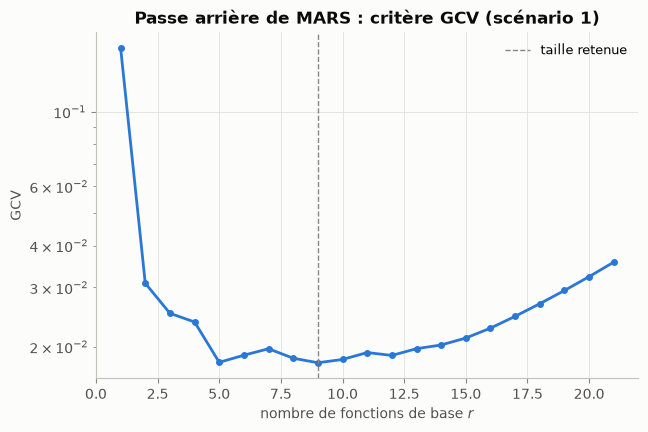

In [14]:
gcv = [g for (_, _, g) in mars1.path_]
tailles = [len(c) for (c, _, _) in mars1.path_]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tailles, gcv, "o-", ms=4, color=BLUE)
ax.axvline(len(mars1.terms_), color=GRAY, ls="--", lw=1, label="taille retenue")
ax.set(title="Passe arrière de MARS : critère GCV (scénario 1)",
       xlabel="nombre de fonctions de base $r$", ylabel="GCV", yscale="log")
ax.legend()
plt.show()

Les termes pris un à un sont peu lisibles : plusieurs combinaisons de paires réfléchies
sont **redondantes** (par exemple $(X_2-t)_+-(t-X_2)_+ = X_2-t$ est linéaire), et les
coefficients se compensent. Il vaut mieux regarder la **surface ajustée**, comparée à la
vraie :

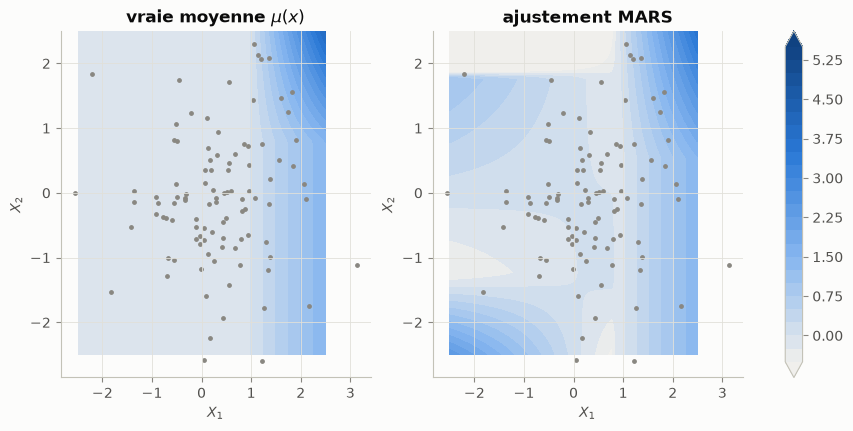

In [15]:
g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 120), np.linspace(-2.5, 2.5, 120))
G = np.c_[g1.ravel(), g2.ravel()]
niv = np.linspace(-0.5, 5.5, 25)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titre, z) in zip(axes, [("vraie moyenne $\\mu(x)$", mu_scenario(G, 1)),
                                 ("ajustement MARS", mars1.predict(G))]):
    cs = ax.contourf(g1, g2, z.reshape(g1.shape), levels=niv, cmap=SEQ, extend="both")
    ax.scatter(Xs[:, 0], Xs[:, 1], s=6, color=GRAY)
    ax.set(title=titre, xlabel="$X_1$", ylabel="$X_2$")
fig.colorbar(cs, ax=axes)
plt.show()

La surface est plate pour $X_1<1$, croît linéairement au-delà, et d'autant plus vite que
$X_2$ dépasse $0.8$ : c'est la structure du scénario 1. Les écarts se situent là où il
n'y a pas de données (coins du domaine).

### MARS sur les données spam

Comme dans le livre, on applique MARS à la réponse 0/1 avec la perte quadratique et des
interactions d'ordre 2, sur les variables transformées $\log(x+0.1)$, puis on classe en
spam si $\hat f(x)>0.5$. Pour limiter le temps de calcul, on se contente de 31 termes et
de 8 nœuds candidats par variable (le livre va jusqu'à une centaine de termes).

In [16]:
Xl = np.log(X + 0.1)
mars_spam = MARS(max_terms=31, max_degree=2, n_knots=8).fit(Xl[train], ytr)
err_mars = np.mean((mars_spam.predict(Xl[test]) > 0.5) != yte)
print("termes retenus par GCV : %d   erreur test : %.3f" % (len(mars_spam.terms_), err_mars))

termes retenus par GCV : 20   erreur test : 0.068


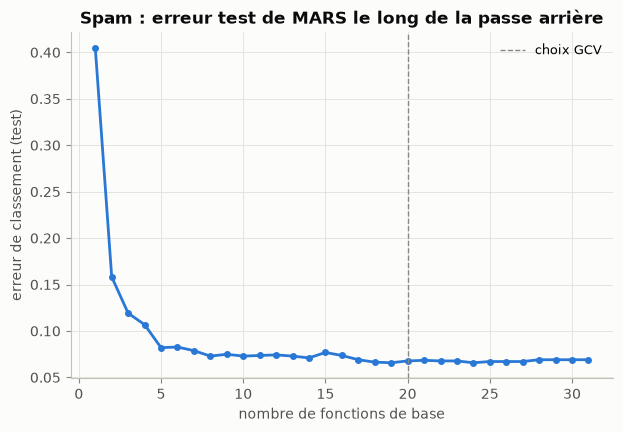

In [17]:
rangs, err_r = [], []
for cols, _, _ in mars_spam.path_:
    termes = [mars_spam.forward_terms_[c] for c in cols]
    D = mars_spam._design(Xl[train], termes)
    b = np.linalg.lstsq(D, ytr, rcond=None)[0]
    rangs.append(len(cols))
    err_r.append(np.mean((mars_spam._design(Xl[test], termes) @ b > 0.5) != yte))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(rangs, err_r, "o-", ms=4, color=BLUE)
ax.axvline(len(mars_spam.terms_), color=GRAY, ls="--", lw=1, label="choix GCV")
ax.set(title="Spam : erreur test de MARS le long de la passe arrière",
       xlabel="nombre de fonctions de base", ylabel="erreur de classement (test)")
ax.legend()
plt.show()

Comme dans la figure 9.12 du livre, l'erreur décroît rapidement puis se stabilise ; notre
version réduite plafonne vers 6 à 7 % (le livre : 5.5 %, avec des modèles bien plus
grands). Les premières interactions retenues :

In [18]:
inter = [t for t in mars_spam.describe(SPAM_NAMES) if t.count(")+") == 2]
for t in inter[:6]:
    print(t)

-0.4093 * (-1.73 - ch$)+ * (-0.868 - remove)+
-0.0383 * (-0.942 - hp)+ * (5.77 - CAPTOT)+
+0.2994 * (-0.942 - hp)+ * (-1.71 - edu)+
+0.0698 * (-0.942 - hp)+ * (george - 0)+
+0.0972 * (-0.942 - hp)+ * (0 - george)+
+0.2027 * (-1.73 - ch$)+ * (free - -0.274)+


### MARS pour la classification et lien avec CART

- **Classification** : pour deux classes, on code 0/1 et on régresse (comme ci-dessus) ;
  pour $K$ classes, on régresse les $K$ indicatrices sur une base commune (avec le risque
  de masquage vu en section 4.2) ; PolyMARS adapte la passe avant à la vraisemblance
  logistique multinomiale.
- **Lien avec CART.** Remplaçons dans MARS les charnières par des **fonctions marches**
  $\mathbb 1(x-t>0)$ et $\mathbb 1(x-t\le 0)$, et imposons qu'un terme multiplié par
  une paire candidate soit **remplacé** par ses deux produits (il n'est plus disponible).
  La passe avant devient exactement la croissance d'un arbre CART : multiplier une
  indicatrice de nœud par une paire de marches, c'est couper ce nœud. C'est la seconde
  règle qui interdit de couper deux fois le même nœud et empêche CART de représenter les
  effets additifs ; MARS s'en affranchit.
- **Variables qualitatives** : MARS considère les partitions des modalités en deux
  groupes, chacune donnant une paire d'indicatrices traitée comme une paire réfléchie.

> **À retenir.** MARS construit pas à pas un modèle $\beta_0+\sum_m\beta_mh_m(X)$ avec des
> produits de **fonctions charnières** $(X_j-t)_+$, $(t-X_j)_+$ ; la passe arrière avec
> GCV ($c=3$ paramètres par nœud) choisit la taille. Plus lisse que CART et capable de
> représenter des effets additifs, il est idéal pour des interactions de bas ordre.

## 3. Mélanges hiérarchiques d'experts (HME)

Un HME est un **arbre à coupures douces** : en chaque nœud interne, une observation part
à gauche ou à droite avec une **probabilité** qui dépend de $x$ ; aux feuilles, on ajuste
un modèle linéaire (ou logistique) au lieu d'une constante. Les coupures sont des
fonctions d'une **combinaison linéaire** des entrées et peuvent être multiples
($K$ branches).

Vocabulaire : les feuilles sont des **experts**, les nœuds internes des **réseaux de
portes** (*gating networks*). On suppose que $x$ contient un 1 en première coordonnée
(pour l'intercept). La porte du sommet a pour sorties (éq. (9.25))
$$g_j(x,\gamma_j) = \frac{e^{\gamma_j^Tx}}{\sum_{k=1}^K e^{\gamma_k^Tx}},\qquad
j=1,\dots,K,$$
la probabilité d'envoyer $x$ dans la branche $j$ (une régression logistique
multinomiale). Au second niveau, $g_{\ell\mid j}(x,\gamma_{j\ell})$ a la même forme
(éq. (9.26)).

> **Remarque.** Pour $K=2$, $g_1 = 1/(1+e^{-(\gamma_1-\gamma_2)^Tx})$ est une courbe
> logistique. Si un coefficient tend vers l'infini, la pente devient infinie et la
> probabilité vaut 0 ou 1 : on retrouve une coupure **dure** sur une variable, comme
> dans CART.

Chaque expert est un modèle $\Pr(y\mid x,\theta_{j\ell})$ (éq. (9.27)) : régression
linéaire gaussienne $Y=\beta_{j\ell}^Tx+\varepsilon$, $\varepsilon\sim\mathcal
N(0,\sigma_{j\ell}^2)$ (éq. (9.28)), ou régression logistique (éq. (9.29)). Le modèle
complet est un **mélange** (éq. (9.30)) :
$$\Pr(y\mid x,\Psi) = \sum_{j=1}^K g_j(x,\gamma_j)\sum_{\ell=1}^K g_{\ell\mid
j}(x,\gamma_{j\ell})\,\Pr(y\mid x,\theta_{j\ell}).$$

### Rappel : l'algorithme EM pour un mélange

On maximise la log-vraisemblance $\sum_i\log\Pr(y_i\mid x_i,\Psi)$. Le logarithme d'une
somme est difficile à maximiser directement ; l'algorithme **EM** (section 8.5) introduit
des **variables latentes** $\Delta_j\in\{0,1\}$ indiquant la branche « réellement »
empruntée. Si on les connaissait, le problème se découperait : une régression par
expert sur ses observations, une régression logistique pour la porte. EM alterne :

- **étape E** : calculer l'espérance des $\Delta_j$ sachant les données et les
  paramètres courants (les « responsabilités ») :
  $h_{ij} = \dfrac{g_j(x_i)\Pr(y_i\mid x_i,\theta_j)}{\sum_k g_k(x_i)\Pr(y_i\mid
  x_i,\theta_k)}$ ;
- **étape M** : ré-estimer chaque expert par moindres carrés **pondérés** par $h_{ij}$,
  et la porte par une régression logistique dont les « réponses » sont les profils
  $(h_{i1},\dots,h_{iK})$.

Chaque itération fait croître la vraisemblance.

### Un HME à un niveau, deux experts

Simulons des données issues d'un tel modèle : chaque observation est produite par
l'expert 1, $y = 1+0.5x+\varepsilon$, ou par l'expert 2, $y = 4-x+\varepsilon$
($\varepsilon\sim\mathcal N(0,0.3^2)$), l'expert 2 étant choisi avec la probabilité
$s(x)=\sigma(3(x-1))$ : la « porte » bascule **progressivement** autour de $x=1$. La
moyenne conditionnelle $f(x) = (1-s(x))(1+0.5x)+s(x)(4-x)$ est un mélange lisse des
deux droites.

In [19]:
Nh = 300
xh = np.sort(rng.uniform(-3, 4, Nh))
s_vraie = sig(3 * (xh - 1))
fh = (1 - s_vraie) * (1 + 0.5 * xh) + s_vraie * (4 - xh)
choix2 = rng.uniform(size=Nh) < s_vraie
yh = np.where(choix2, 4 - xh, 1 + 0.5 * xh) + 0.3 * rng.randn(Nh)
Xh = np.column_stack([np.ones(Nh), xh])

In [20]:
def hme_em(Xh, yh, n_iter=200):
    """EM pour un mélange de 2 experts linéaires gaussiens avec porte logistique."""
    gam = np.array([0.0, 1.0])            # porte : P(expert 2 | x) = sigma(gam . x)
    q = np.quantile(Xh[:, 1], [0.25, 0.75])
    beta = [np.linalg.lstsq(Xh[Xh[:, 1] < q[0]], yh[Xh[:, 1] < q[0]], rcond=None)[0],
            np.linalg.lstsq(Xh[Xh[:, 1] > q[1]], yh[Xh[:, 1] > q[1]], rcond=None)[0]]
    s2 = [1.0, 1.0]
    loglik = []
    for _ in range(n_iter):
        g2 = sig(Xh @ gam)
        g = np.column_stack([1 - g2, g2])
        dens = np.column_stack([np.exp(-0.5 * (yh - Xh @ beta[j]) ** 2 / s2[j])
                                / np.sqrt(2 * np.pi * s2[j]) for j in range(2)])
        mix = (g * dens).sum(1)
        loglik.append(np.log(mix).sum())
        H = g * dens / mix[:, None]                       # étape E
        for j in range(2):                                # étape M : experts
            w = H[:, j]
            beta[j] = np.linalg.solve(Xh.T @ (w[:, None] * Xh), Xh.T @ (w * yh))
            s2[j] = np.sum(w * (yh - Xh @ beta[j]) ** 2) / w.sum()
        for _ in range(5):                                # étape M : porte (Newton)
            pg = sig(Xh @ gam)
            grad = Xh.T @ (H[:, 1] - pg)
            hess = Xh.T @ ((pg * (1 - pg))[:, None] * Xh)
            gam = gam + np.linalg.solve(hess + 1e-8 * np.eye(2), grad)
    return gam, beta, s2, np.array(loglik)

gam_h, beta_h, s2_h, ll = hme_em(Xh, yh)
print("porte : gamma =", np.round(gam_h, 2), " (vrai : (-3, 3), transition en x = 1)")
print("expert 1 :", np.round(beta_h[0], 2), "  expert 2 :", np.round(beta_h[1], 2))
print("log-vraisemblance croissante :", np.all(np.diff(ll) > -1e-8))

porte : gamma = [-2.7   2.54]  (vrai : (-3, 3), transition en x = 1)
expert 1 : [1.   0.51]   expert 2 : [ 4.14 -1.03]
log-vraisemblance croissante : True


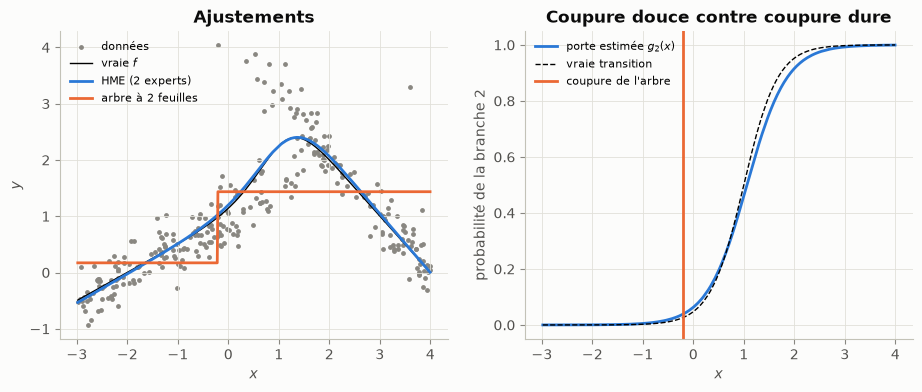

In [21]:
g2 = sig(Xh @ gam_h)
pred_hme = (1 - g2) * (Xh @ beta_h[0]) + g2 * (Xh @ beta_h[1])
arbre_h = ArbreCART(task="regression", max_leaves=2).fit(xh[:, None], yh)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.scatter(xh, yh, s=6, color=GRAY, label="données")
ax.plot(xh, fh, color="k", lw=1, label="vraie $f$")
ax.plot(xh, pred_hme, color=BLUE, label="HME (2 experts)")
ax.plot(xh, arbre_h.predict(xh[:, None]), color=ORANGE, label="arbre à 2 feuilles")
ax.set(title="Ajustements", xlabel="$x$", ylabel="$y$")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(xh, g2, color=BLUE, label="porte estimée $g_2(x)$")
ax.plot(xh, s_vraie, color="k", lw=1, ls="--", label="vraie transition")
ax.axvline(arbre_h.threshold[0], color=ORANGE, label="coupure de l'arbre")
ax.set(title="Coupure douce contre coupure dure", xlabel="$x$",
       ylabel="probabilité de la branche 2")
ax.legend(fontsize=8)
plt.show()

Le HME retrouve les deux experts et une porte **progressive** proche de la vraie ;
sa prédiction $\sum_j g_j(x)\hat\beta_j^Tx$ est lisse, alors que l'arbre ne fait qu'une
marche. En contrepartie, il n'existe pas de méthode satisfaisante pour choisir la
**topologie** d'un HME (on fixe un arbre, souvent issu de CART), et l'accent est mis sur
la prédiction plus que sur l'interprétation.

## 4. Données manquantes

### Mécanismes de manque

Notons $y$ la réponse, $X$ la matrice $N\times p$ des entrées (certaines manquantes),
$X_{\text{obs}}$ les entrées observées, $Z=(y,X)$, $Z_{\text{obs}}=(y,X_{\text{obs}})$,
et $R$ la matrice indicatrice des valeurs manquantes ($R_{ij}=1$ si $x_{ij}$ manque).

- Les données sont **manquantes au hasard** (MAR) si la loi de $R$ ne dépend des données
  qu'à travers leur partie observée (éq. (9.31)) : $\Pr(R\mid Z,\theta) = \Pr(R\mid
  Z_{\text{obs}},\theta)$.
- Elles sont **manquantes complètement au hasard** (MCAR) si la loi de $R$ ne dépend pas
  du tout des données (éq. (9.32)) : $\Pr(R\mid Z,\theta)=\Pr(R\mid\theta)$.

MCAR est plus fort que MAR, et la plupart des méthodes d'imputation le supposent. Si une
mesure n'a pas été faite **parce que** le patient était trop malade, la donnée n'est ni
MCAR ni MAR : l'échantillon observé donne une image **déformée** de la population et
l'imputation est dangereuse. Pour une variable qualitative, on peut diagnostiquer le
problème en codant « manquant » comme une modalité et en regardant si elle prédit la
réponse.

### Trois façons de faire (sous MCAR)

1. **Supprimer** les observations incomplètes (acceptable si elles sont peu nombreuses).
2. Laisser l'**algorithme** gérer les manques : CART (coupures de substitution), MARS et
   PRIM (approches similaires) ; dans un modèle additif, les observations où $x_j$ manque
   sont omises lors du lissage contre $x_j$ et reçoivent $\hat f_j=0$, c'est-à-dire la
   valeur moyenne puisque les fonctions sont centrées.
3. **Imputer** les valeurs manquantes avant l'apprentissage : par la moyenne ou la
   médiane, ou mieux, par la prédiction d'un modèle de $X_j$ en fonction des autres
   entrées - un arbre CART est un excellent « moteur d'imputation ».

### Simulation : biais selon le mécanisme

On simule $(X_1,X_2,X_3)$ gaussiens corrélés (corrélation 0.7 entre $X_1$ et $X_2$),
$Y = 1 + 2X_1 + X_2 - X_3 + \varepsilon$, et l'on supprime environ 40 % des valeurs de
$X_1$ selon trois mécanismes : **MCAR** (au hasard), **MAR** (plus souvent quand $X_2$
est grand) et **non MAR** (plus souvent quand $X_1$ lui-même est grand). On compare
l'estimation de la moyenne de $X_1$ (vraie valeur 0) et du coefficient $\beta_1$
(vraie valeur 2) par trois stratégies.